In [26]:
"""
STEP 4: MODEL INTERPRETABILITY ANALYSIS
==========================================

Purpose:
- Extract and interpret what the LOCAL models learned
- Analyze LNU (linear) coefficients across z-heights
- Validate learned relationships against physics expectations
- Show the KEY ADVANTAGE of local models: interpretability

What we analyze:
- How does each coefficient change with z-height?
- Do the learned relationships make physical sense?
- What physics insights can we extract?

For LNU model at each z-height:
  U_x = β₀ + β₁·x_norm + β₂·U_ref + β₃·type_Uniform + β₄·type_ABL+const + ...

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')


In [27]:
# ============================================================================
# CONFIGURATION
# ============================================================================

RESULTS_FILE = REPORTS_DIR / 'step3_results.pkl'
OUTPUT_DIR = FIGURES_DIR

# Cube geometry
H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075
X_CUBE_BACK = 0.090

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

print("="*80)
print(" "*15 + "STEP 3.5: MODEL INTERPRETABILITY ANALYSIS")
print("="*80)
print("\nPurpose: Extract and interpret what the LOCAL models learned")
print("Focus: LNU (linear) coefficients - the interpretable model")


               STEP 3.5: MODEL INTERPRETABILITY ANALYSIS

Purpose: Extract and interpret what the LOCAL models learned
Focus: LNU (linear) coefficients - the interpretable model


In [28]:
# ============================================================================
# LOAD RESULTS
# ============================================================================

print(f"\n{'='*80}")
print("LOADING STEP 3 RESULTS")
print("="*80)

with open(RESULTS_FILE, 'rb') as f:
    results = pickle.load(f)

models = results['models']
metrics = results['metrics']
z_heights = results['z_heights']
feature_names = results['feature_names']
H_CUBE = results.get('H_CUBE', 0.015)
USE_FLOW_REGIME = results.get('USE_FLOW_REGIME', False)

print(f"✓ Loaded results for {len(z_heights)} z-heights")
print(f"✓ Features: {feature_names}")
print(f"✓ Flow regime: {'ENABLED' if USE_FLOW_REGIME else 'DISABLED'}")



LOADING STEP 3 RESULTS
✓ Loaded results for 202 z-heights
✓ Features: ['x_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam', 'regime_upstream', 'regime_over_cube', 'regime_wake', 'regime_far_downstream']
✓ Flow regime: ENABLED


In [29]:
# ============================================================================
# EXTRACT LNU COEFFICIENTS
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING LNU COEFFICIENTS")
print("="*80)

print(f"\nLNU model equation:")
print(f"  U_x = β₀ + β₁·x_norm + β₂·U_ref + β₃·type_0 + β₄·type_1 + ...")
print(f"\nExtracting coefficients at each z-height...")

# Storage for coefficients
coefficients = {
    'z': [],
    'z_norm': [],
    'intercept': [],
}
for fname in feature_names:
    coefficients[fname] = []

# Also store metrics
coefficients['R2'] = []
coefficients['RMSE'] = []

# Extract coefficients from each LNU model
for z in z_heights:
    model_LNU = models[z]['LNU']
    
    coefficients['z'].append(z)
    coefficients['z_norm'].append(z / H_CUBE)
    coefficients['intercept'].append(model_LNU.intercept_)
    
    for i, fname in enumerate(feature_names):
        coefficients[fname].append(model_LNU.coef_[i])
    
    coefficients['R2'].append(metrics[z]['LNU']['R2'])
    coefficients['RMSE'].append(metrics[z]['LNU']['RMSE'])

# Convert to DataFrame
df_coef = pd.DataFrame(coefficients)

print(f"\n✓ Extracted coefficients for {len(df_coef)} z-heights")
print(f"\nCoefficient statistics:")
print(df_coef.describe().round(4))



EXTRACTING LNU COEFFICIENTS

LNU model equation:
  U_x = β₀ + β₁·x_norm + β₂·U_ref + β₃·type_0 + β₄·type_1 + ...

Extracting coefficients at each z-height...

✓ Extracted coefficients for 202 z-heights

Coefficient statistics:
              z    z_norm  intercept    x_norm     U_ref  type_Uniform  \
count  202.0000  202.0000   202.0000  202.0000  202.0000      202.0000   
mean     0.0177    1.1809     2.0124    0.2760    1.2547        0.0212   
std      0.0099    0.6615     1.3090    1.4298    0.7247        0.0360   
min      0.0003    0.0208    -0.1228   -3.1981   -0.1842       -0.1068   
25%      0.0103    0.6875     0.9031   -0.2143    0.6552        0.0159   
50%      0.0175    1.1658     1.5398    0.0008    1.0138        0.0296   
75%      0.0241    1.6040     3.2539    0.3571    2.1262        0.0417   
max      0.0481    3.2083     4.5573    5.5546    2.2221        0.0737   

       type_ABL+const  type_ABL+free  type_ABL+lam  regime_upstream  \
count        202.0000       202.00


ANALYSIS 1: HOW COEFFICIENTS CHANGE WITH HEIGHT


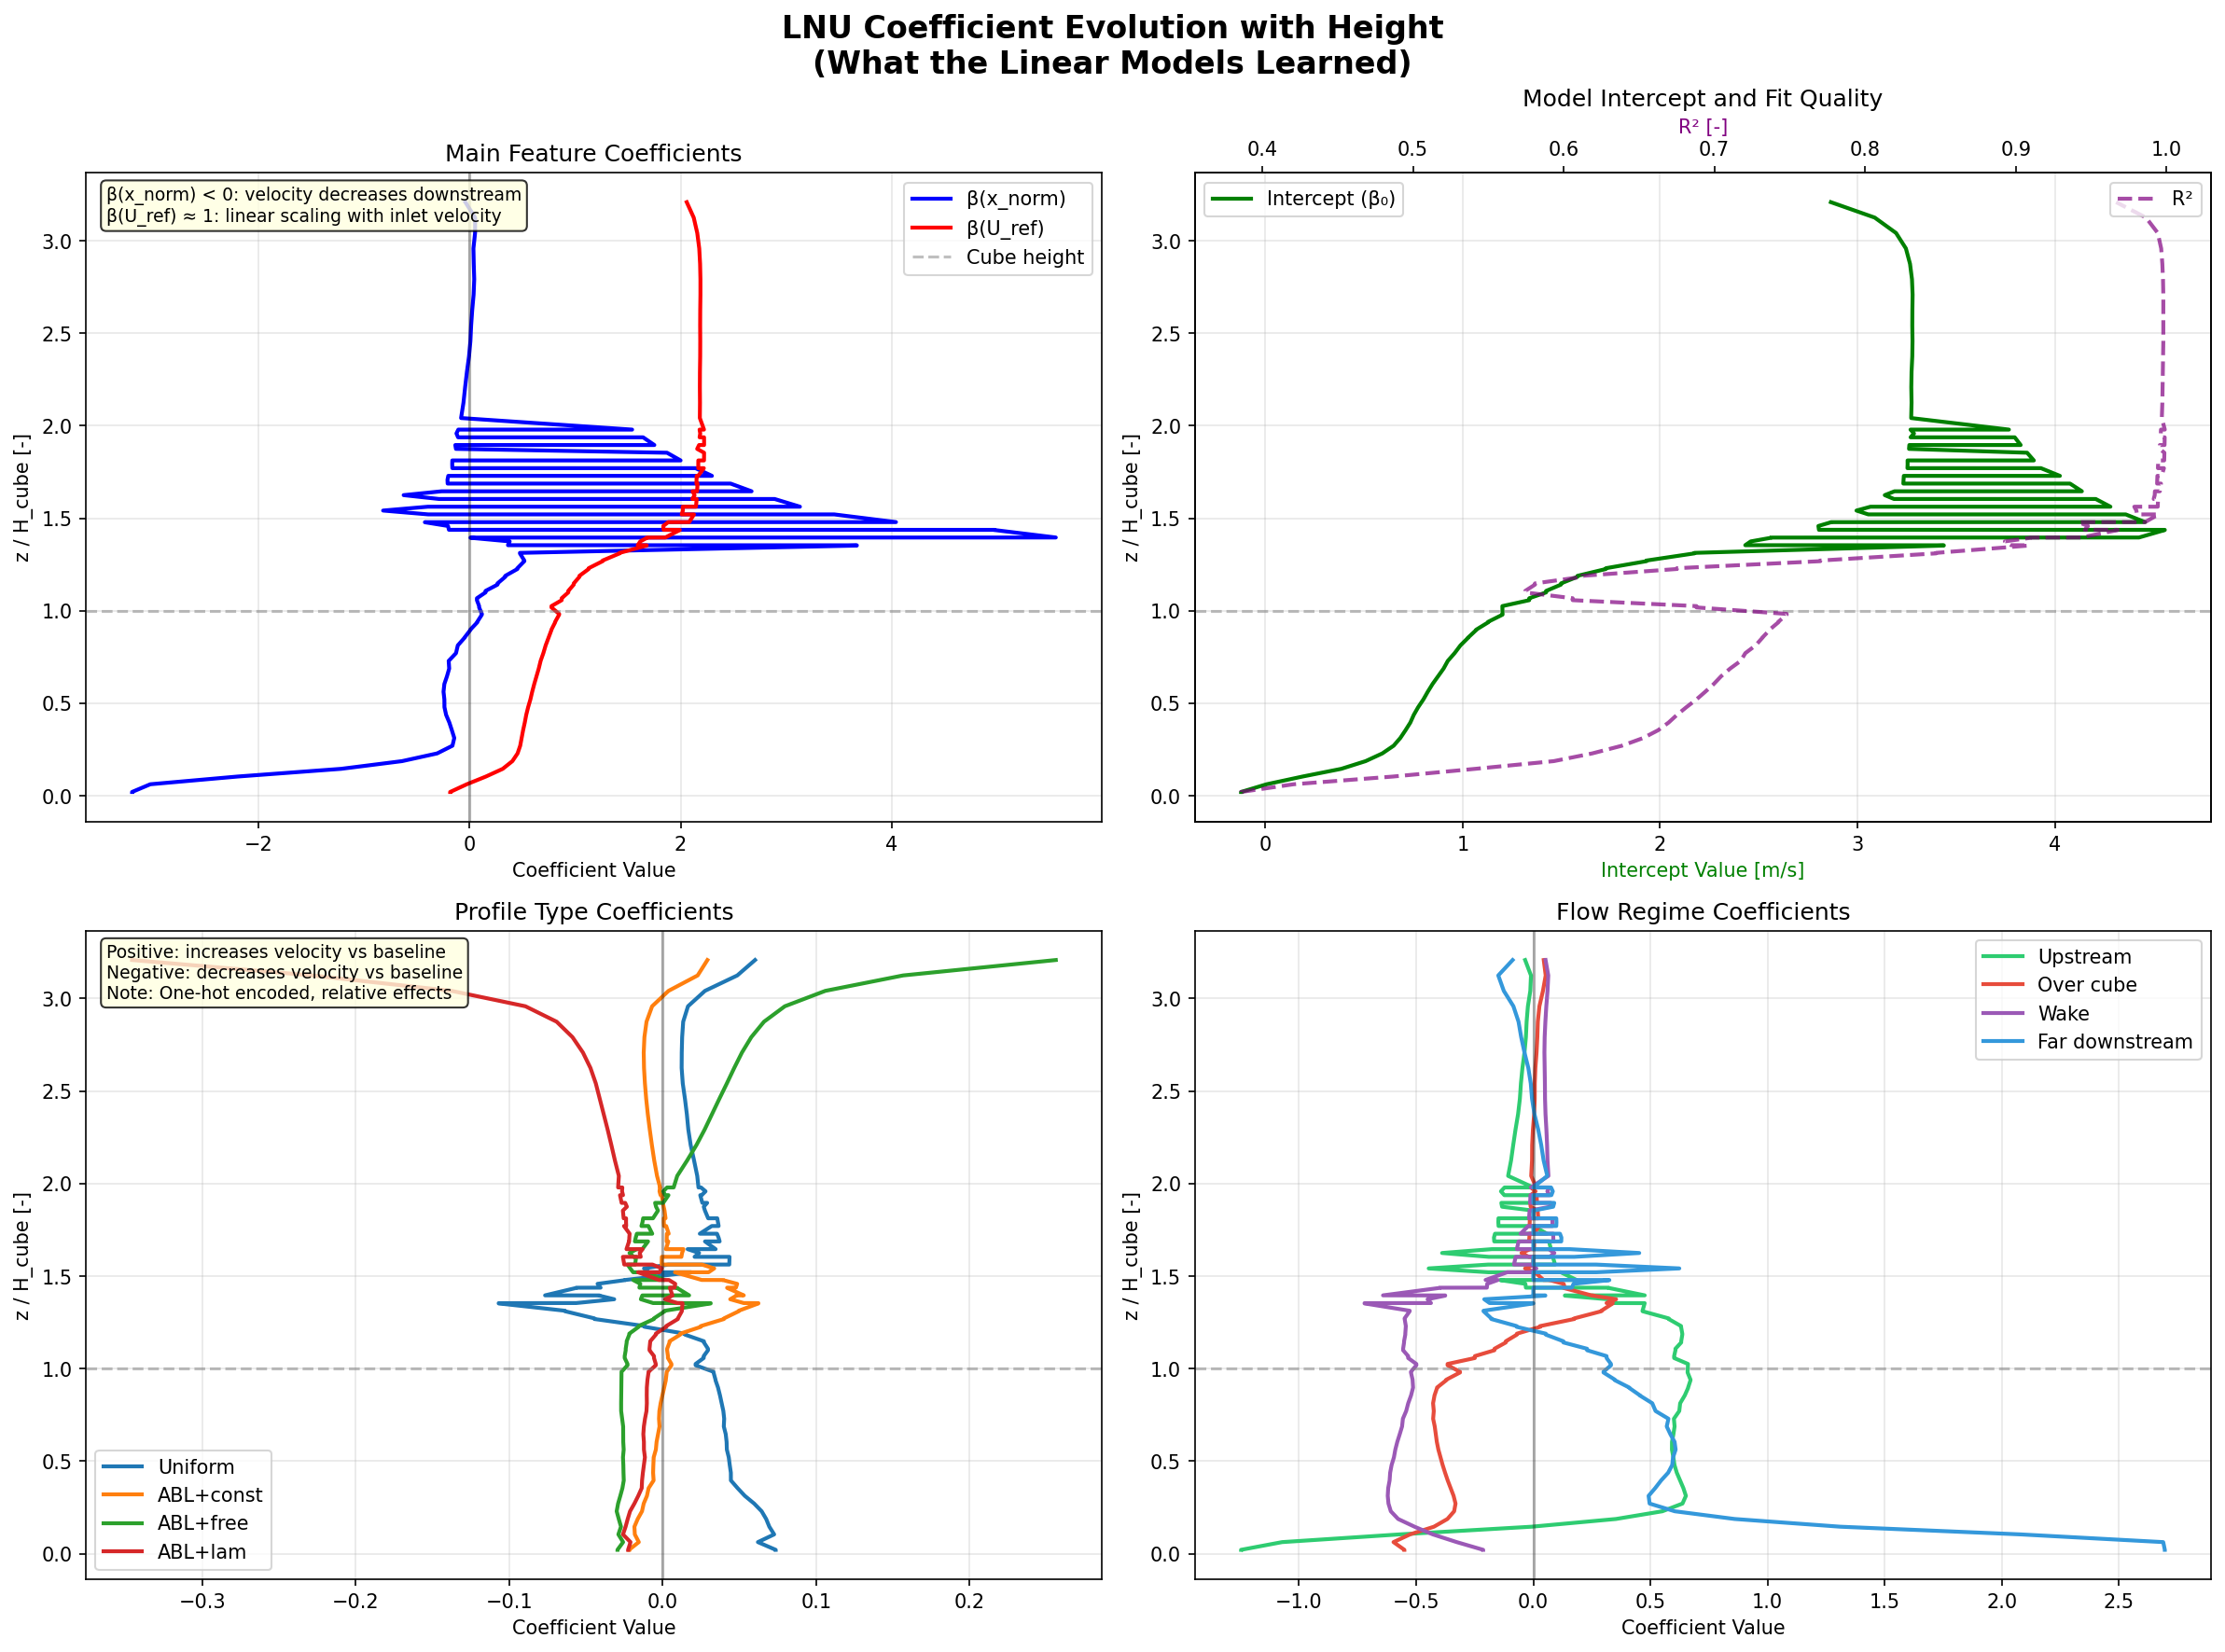

✓ Saved: step3_5_coefficient_evolution.png


In [30]:
# ============================================================================
# ANALYSIS 1: COEFFICIENT EVOLUTION WITH HEIGHT
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 1: HOW COEFFICIENTS CHANGE WITH HEIGHT")
print("="*80)

# Determine which coefficients to plot based on feature set
if USE_FLOW_REGIME:
    main_features = ['x_norm', 'U_ref']
    type_features = ['type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
    regime_features = ['regime_upstream', 'regime_over_cube', 'regime_wake', 'regime_far_downstream']
else:
    main_features = ['x_norm', 'U_ref']
    type_features = ['type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
    regime_features = []

# Create figure with subplots
n_plots = 4 if USE_FLOW_REGIME else 3
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('LNU Coefficient Evolution with Height\n(What the Linear Models Learned)', 
             fontsize=16, fontweight='bold')

# Plot 1: Main coefficients (x_norm, U_ref)
ax = axes[0, 0]
ax.plot(df_coef['x_norm'], df_coef['z_norm'], 'b-', linewidth=2, label='β(x_norm)')
ax.plot(df_coef['U_ref'], df_coef['z_norm'], 'r-', linewidth=2, label='β(U_ref)')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='Cube height')
ax.axvline(0, color='black', linestyle='-', alpha=0.3)
ax.set_xlabel('Coefficient Value')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Main Feature Coefficients')
ax.legend()
ax.grid(True, alpha=0.3)

# Add interpretation text
ax.text(0.02, 0.98, 
        'β(x_norm) < 0: velocity decreases downstream\n'
        'β(U_ref) ≈ 1: linear scaling with inlet velocity',
        transform=ax.transAxes, fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# Plot 2: Intercept and R²
ax = axes[0, 1]
ax2 = ax.twiny()
ax.plot(df_coef['intercept'], df_coef['z_norm'], 'g-', linewidth=2, label='Intercept (β₀)')
ax2.plot(df_coef['R2'], df_coef['z_norm'], 'purple', linewidth=2, linestyle='--', label='R²', alpha=0.7)
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Intercept Value [m/s]', color='green')
ax2.set_xlabel('R² [-]', color='purple')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Model Intercept and Fit Quality')
ax.legend(loc='upper left')
ax2.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Plot 3: Profile type coefficients
ax = axes[1, 0]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
labels = ['Uniform', 'ABL+const', 'ABL+free', 'ABL+lam']
for i, (feat, color, label) in enumerate(zip(type_features, colors, labels)):
    if feat in df_coef.columns:
        ax.plot(df_coef[feat], df_coef['z_norm'], color=color, linewidth=2, label=label)

ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(0, color='black', linestyle='-', alpha=0.3)
ax.set_xlabel('Coefficient Value')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Profile Type Coefficients')
ax.legend()
ax.grid(True, alpha=0.3)

# Add interpretation
ax.text(0.02, 0.98, 
        'Positive: increases velocity vs baseline\n'
        'Negative: decreases velocity vs baseline\n'
        'Note: One-hot encoded, relative effects',
        transform=ax.transAxes, fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# Plot 4: Flow regime coefficients (if enabled) or RMSE
ax = axes[1, 1]
if USE_FLOW_REGIME and regime_features:
    colors = ['#2ecc71', '#e74c3c', '#9b59b6', '#3498db']
    labels = ['Upstream', 'Over cube', 'Wake', 'Far downstream']
    for feat, color, label in zip(regime_features, colors, labels):
        if feat in df_coef.columns:
            ax.plot(df_coef[feat], df_coef['z_norm'], color=color, linewidth=2, label=label)
    
    ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(0, color='black', linestyle='-', alpha=0.3)
    ax.set_xlabel('Coefficient Value')
    ax.set_ylabel('z / H_cube [-]')
    ax.set_title('Flow Regime Coefficients')
    ax.legend()
    ax.grid(True, alpha=0.3)
else:
    # Plot RMSE instead
    ax.plot(df_coef['RMSE'], df_coef['z_norm'], 'r-', linewidth=2)
    ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
    ax.set_xlabel('RMSE [m/s]')
    ax.set_ylabel('z / H_cube [-]')
    ax.set_title('Model Error by Height')
    ax.grid(True, alpha=0.3)
    
    # Highlight problem zone
    ax.axhspan(0.8, 1.5, alpha=0.2, color='red', label='High error zone')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step3_5_coefficient_evolution.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_5_coefficient_evolution.png")
plt.close()

In [31]:
# ============================================================================
# ANALYSIS 2: PHYSICS INTERPRETATION
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 2: PHYSICS INTERPRETATION")
print("="*80)

# Key heights for analysis
key_heights = {
    'Near ground (z/H=0.1)': 0.1,
    'Half cube (z/H=0.5)': 0.5,
    'Cube top (z/H=1.0)': 1.0,
    'Shear layer (z/H=1.3)': 1.3,
    'Above cube (z/H=2.0)': 2.0,
    'Freestream (z/H=3.0)': 3.0,
}

print("\n📊 COEFFICIENT VALUES AT KEY HEIGHTS:")
print("-" * 80)

for name, z_target in key_heights.items():
    # Find closest z-height
    idx = np.argmin(np.abs(df_coef['z_norm'] - z_target))
    row = df_coef.iloc[idx]
    
    print(f"\n{name} (actual z/H = {row['z_norm']:.2f}):")
    print(f"  β(x_norm) = {row['x_norm']:+.4f}  → {'Velocity decreases downstream' if row['x_norm'] < 0 else 'Velocity increases downstream'}")
    print(f"  β(U_ref)  = {row['U_ref']:+.4f}  → Velocity scales as {row['U_ref']:.2f}×U_ref")
    print(f"  R² = {row['R2']:.3f}, RMSE = {row['RMSE']:.3f} m/s")



ANALYSIS 2: PHYSICS INTERPRETATION

📊 COEFFICIENT VALUES AT KEY HEIGHTS:
--------------------------------------------------------------------------------

Near ground (z/H=0.1) (actual z/H = 0.10):
  β(x_norm) = -2.1998  → Velocity decreases downstream
  β(U_ref)  = +0.1545  → Velocity scales as 0.15×U_ref
  R² = 0.487, RMSE = 1.015 m/s

Half cube (z/H=0.5) (actual z/H = 0.48):
  β(x_norm) = -0.2382  → Velocity decreases downstream
  β(U_ref)  = +0.5549  → Velocity scales as 0.55×U_ref
  R² = 0.681, RMSE = 0.971 m/s

Cube top (z/H=1.0) (actual z/H = 0.98):
  β(x_norm) = +0.1165  → Velocity increases downstream
  β(U_ref)  = +0.8488  → Velocity scales as 0.85×U_ref
  R² = 0.748, RMSE = 0.835 m/s

Shear layer (z/H=1.3) (actual z/H = 1.31):
  β(x_norm) = +0.4768  → Velocity increases downstream
  β(U_ref)  = +1.4220  → Velocity scales as 1.42×U_ref
  R² = 0.847, RMSE = 0.695 m/s

Above cube (z/H=2.0) (actual z/H = 1.98):
  β(x_norm) = +1.5405  → Velocity increases downstream
  β(U_ref)  

In [32]:
# ============================================================================
# ANALYSIS 3: PHYSICS VALIDATION
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 3: PHYSICS VALIDATION")
print("="*80)

print("\n🔬 CHECKING LEARNED RELATIONSHIPS AGAINST PHYSICS:")

# Check 1: U_ref scaling
u_ref_coef_mean = df_coef['U_ref'].mean()
u_ref_coef_std = df_coef['U_ref'].std()
print(f"\n1. U_ref Scaling:")
print(f"   Mean β(U_ref) = {u_ref_coef_mean:.3f} ± {u_ref_coef_std:.3f}")
if 0.8 < u_ref_coef_mean < 1.2:
    print(f"   ✅ CORRECT: Velocity scales approximately linearly with U_ref")
    print(f"   Physics: This confirms Reynolds similarity in the flow")
else:
    print(f"   ⚠️ UNEXPECTED: Non-linear scaling with U_ref")

# Check 2: x_norm effect in wake
wake_mask = df_coef['z_norm'] < 1.0  # Below cube height
x_norm_wake = df_coef.loc[wake_mask, 'x_norm'].mean()
print(f"\n2. Streamwise Effect (below cube height):")
print(f"   Mean β(x_norm) = {x_norm_wake:.3f}")
if x_norm_wake < 0:
    print(f"   ✅ CORRECT: Velocity decreases downstream in wake region")
    print(f"   Physics: Wake deficit causes velocity reduction behind cube")
else:
    print(f"   ⚠️ CHECK: Positive x-coefficient below cube height")

# Check 3: Profile type effects
print(f"\n3. Inlet Profile Effects:")
if 'type_Uniform' in df_coef.columns:
    for feat in type_features:
        if feat in df_coef.columns:
            coef_mean = df_coef[feat].mean()
            print(f"   β({feat:20s}) = {coef_mean:+.3f}")
    print(f"   Note: One-hot encoding means these are relative to each other")
    print(f"   Physics: Different inlet profiles create different velocity distributions")

# Check 4: R² variation with height
low_r2_mask = df_coef['R2'] < 0.7
n_low_r2 = low_r2_mask.sum()
print(f"\n4. Model Quality Variation:")
print(f"   Heights with R² < 0.7: {n_low_r2}/{len(df_coef)} ({100*n_low_r2/len(df_coef):.1f}%)")
if n_low_r2 > 0:
    low_r2_heights = df_coef.loc[low_r2_mask, 'z_norm']
    print(f"   Problem heights (z/H): {low_r2_heights.min():.2f} to {low_r2_heights.max():.2f}")
    print(f"   Physics: These are likely in the shear layer / separation region")



ANALYSIS 3: PHYSICS VALIDATION

🔬 CHECKING LEARNED RELATIONSHIPS AGAINST PHYSICS:

1. U_ref Scaling:
   Mean β(U_ref) = 1.255 ± 0.725
   ⚠️ UNEXPECTED: Non-linear scaling with U_ref

2. Streamwise Effect (below cube height):
   Mean β(x_norm) = -0.563
   ✅ CORRECT: Velocity decreases downstream in wake region
   Physics: Wake deficit causes velocity reduction behind cube

3. Inlet Profile Effects:
   β(type_Uniform        ) = +0.021
   β(type_ABL+const      ) = +0.007
   β(type_ABL+free       ) = -0.012
   β(type_ABL+lam        ) = -0.016
   Note: One-hot encoding means these are relative to each other
   Physics: Different inlet profiles create different velocity distributions

4. Model Quality Variation:
   Heights with R² < 0.7: 77/202 (38.1%)
   Problem heights (z/H): 0.02 to 1.23
   Physics: These are likely in the shear layer / separation region


In [33]:
# ============================================================================
# ANALYSIS 4: DETAILED COEFFICIENT TABLE
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 4: COEFFICIENT TABLE")
print("="*80)

# Create summary table at key heights
table_data = []
for name, z_target in key_heights.items():
    idx = np.argmin(np.abs(df_coef['z_norm'] - z_target))
    row = df_coef.iloc[idx]
    table_data.append({
        'Location': name,
        'z/H': f"{row['z_norm']:.2f}",
        'β(x_norm)': f"{row['x_norm']:.3f}",
        'β(U_ref)': f"{row['U_ref']:.3f}",
        'R²': f"{row['R2']:.3f}",
        'Interpretation': 'Wake deficit' if row['x_norm'] < -0.05 else ('Acceleration' if row['x_norm'] > 0.05 else 'Neutral')
    })

table_df = pd.DataFrame(table_data)
print("\nTable: LNU Coefficients at Key Heights")
print("-" * 90)
print(table_df.to_string(index=False))
print("-" * 90)

# Save table to CSV
table_df.to_csv(REPORTS_DIR / 'step4_coefficient_table.csv', index=False)
print(f"\n✓ Saved: step4_coefficient_table.csv")



ANALYSIS 4: COEFFICIENT TABLE

Table: LNU Coefficients at Key Heights
------------------------------------------------------------------------------------------
             Location  z/H β(x_norm) β(U_ref)    R² Interpretation
Near ground (z/H=0.1) 0.10    -2.200    0.154 0.487   Wake deficit
  Half cube (z/H=0.5) 0.48    -0.238    0.555 0.681   Wake deficit
   Cube top (z/H=1.0) 0.98     0.117    0.849 0.748   Acceleration
Shear layer (z/H=1.3) 1.31     0.477    1.422 0.847   Acceleration
 Above cube (z/H=2.0) 1.98     1.540    2.221 0.999   Acceleration
 Freestream (z/H=3.0) 2.96     0.036    2.176 0.996        Neutral
------------------------------------------------------------------------------------------

✓ Saved: step4_coefficient_table.csv



CREATING DETAILED VISUALIZATIONS


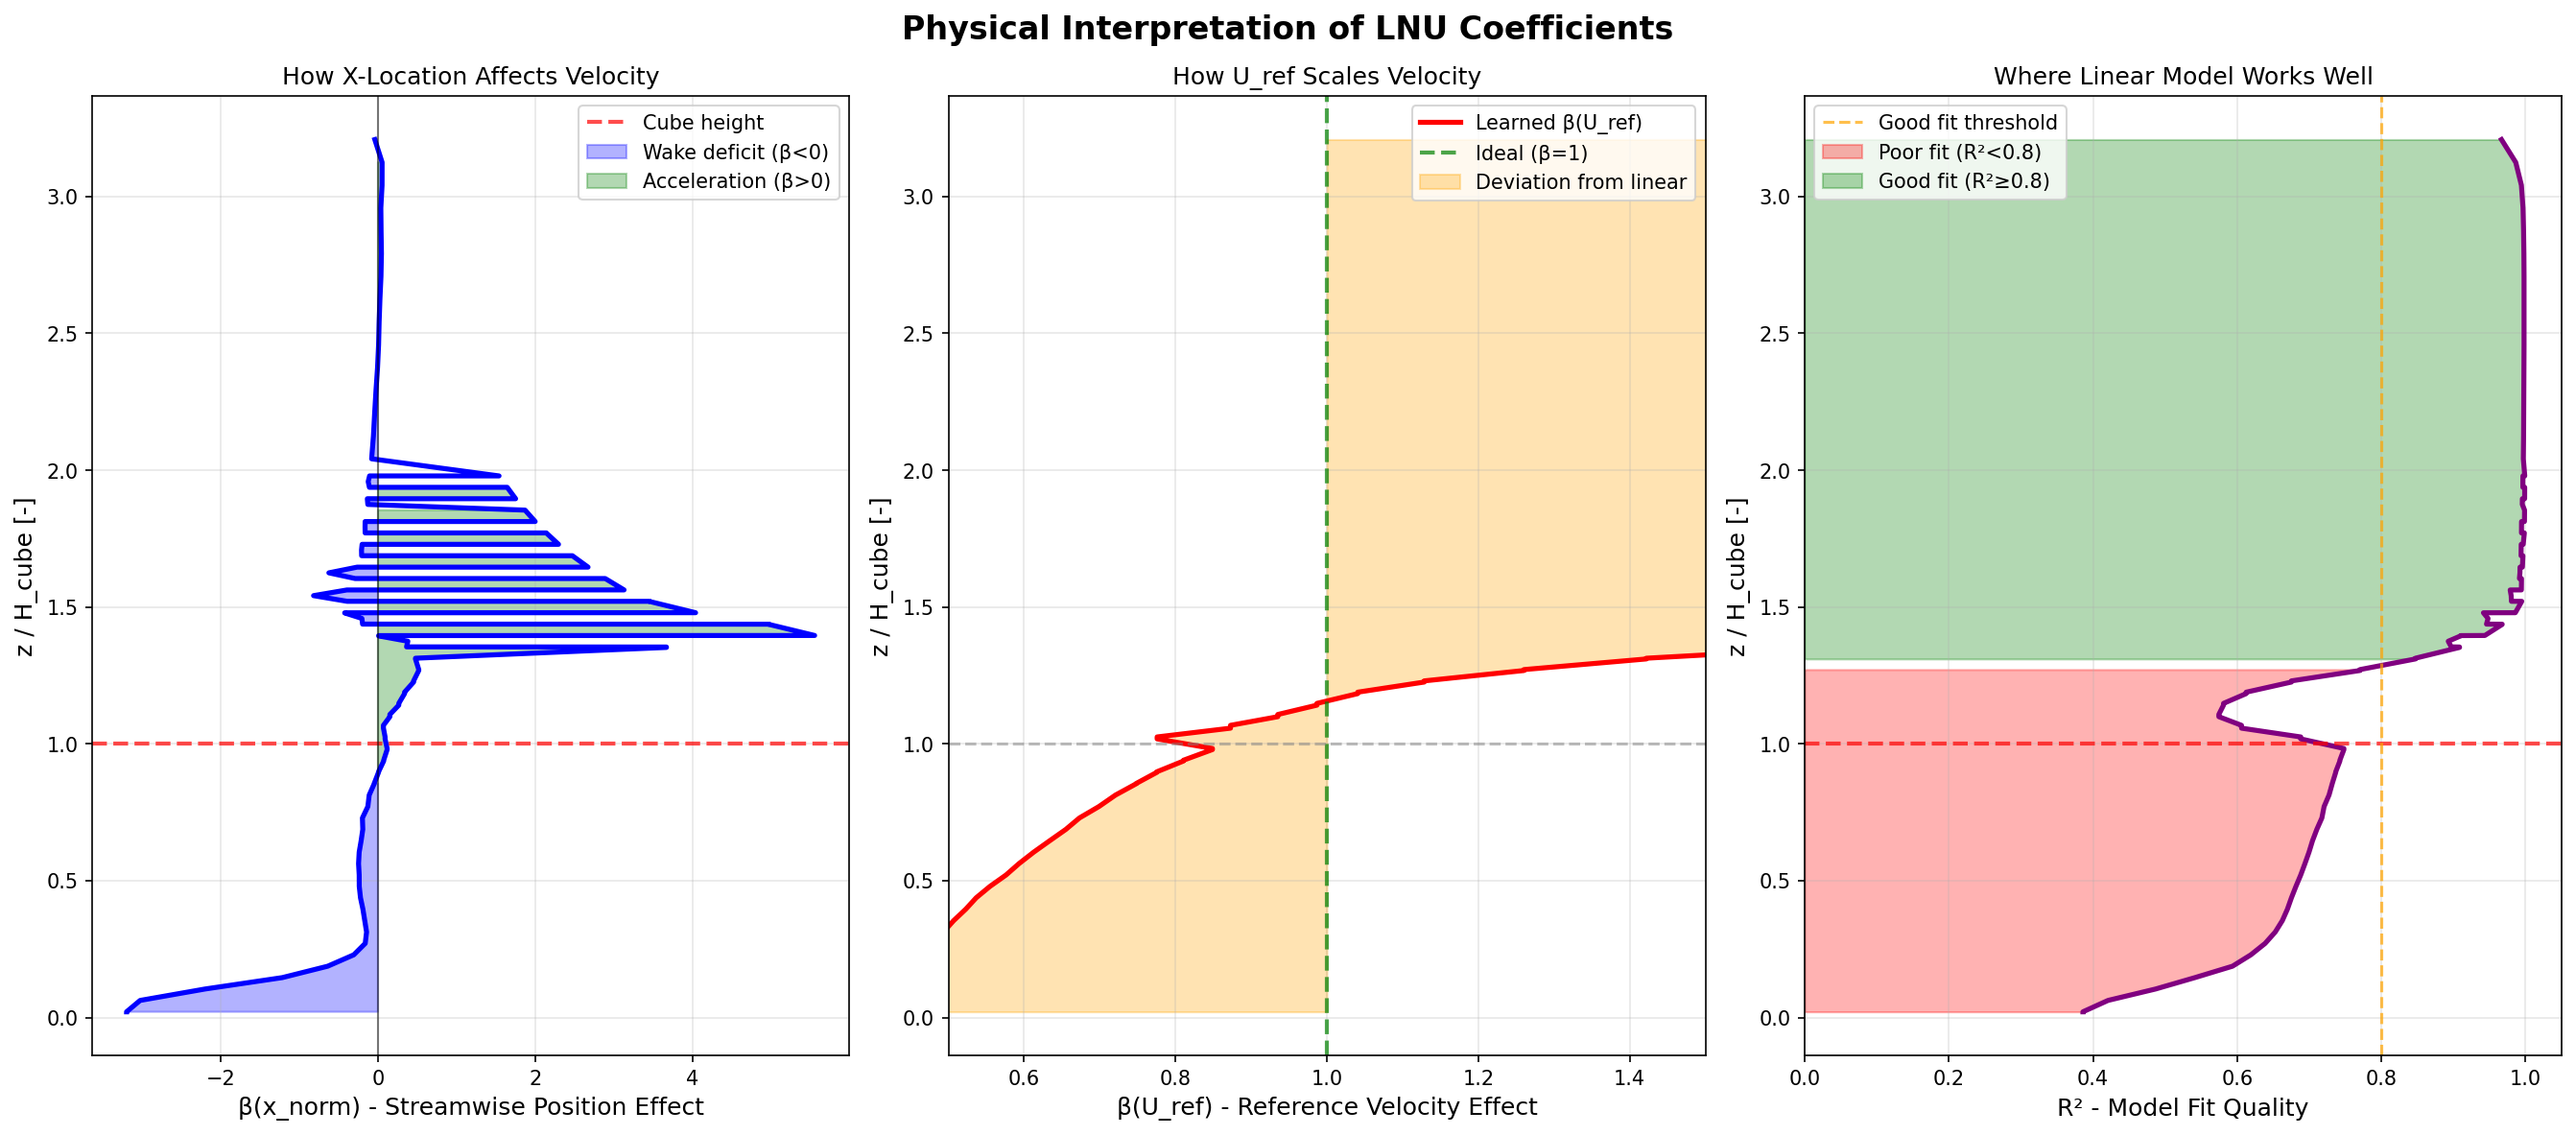

✓ Saved: step4_physics_interpretation.png


In [34]:
# ============================================================================
# VISUALIZATION 2: DETAILED COEFFICIENT PROFILES
# ============================================================================

print(f"\n{'='*80}")
print("CREATING DETAILED VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
fig.suptitle('Physical Interpretation of LNU Coefficients', fontsize=16, fontweight='bold')

# Plot 1: x_norm coefficient with physics zones
ax = axes[0]
ax.plot(df_coef['x_norm'], df_coef['z_norm'], 'b-', linewidth=2.5)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.7, linewidth=2, label='Cube height')
ax.axvline(0, color='black', linestyle='-', alpha=0.5, linewidth=1)

# Shade regions
ax.fill_betweenx(df_coef['z_norm'], df_coef['x_norm'], 0, 
                  where=df_coef['x_norm'] < 0, alpha=0.3, color='blue',
                  label='Wake deficit (β<0)')
ax.fill_betweenx(df_coef['z_norm'], df_coef['x_norm'], 0, 
                  where=df_coef['x_norm'] > 0, alpha=0.3, color='green',
                  label='Acceleration (β>0)')

ax.set_xlabel('β(x_norm) - Streamwise Position Effect', fontsize=12)
ax.set_ylabel('z / H_cube [-]', fontsize=12)
ax.set_title('How X-Location Affects Velocity')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

# Plot 2: U_ref coefficient with ideal line
ax = axes[1]
ax.plot(df_coef['U_ref'], df_coef['z_norm'], 'r-', linewidth=2.5, label='Learned β(U_ref)')
ax.axvline(1.0, color='green', linestyle='--', alpha=0.7, linewidth=2, label='Ideal (β=1)')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)

# Highlight deviation from ideal
ax.fill_betweenx(df_coef['z_norm'], df_coef['U_ref'], 1.0, 
                  alpha=0.3, color='orange', label='Deviation from linear')

ax.set_xlabel('β(U_ref) - Reference Velocity Effect', fontsize=12)
ax.set_ylabel('z / H_cube [-]', fontsize=12)
ax.set_title('How U_ref Scales Velocity')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
ax.set_xlim([0.5, 1.5])

# Plot 3: R² profile with problem zones
ax = axes[2]
ax.plot(df_coef['R2'], df_coef['z_norm'], 'purple', linewidth=2.5)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax.axvline(0.8, color='orange', linestyle='--', alpha=0.7, label='Good fit threshold')

# Shade problem regions
ax.fill_betweenx(df_coef['z_norm'], 0, df_coef['R2'], 
                  where=df_coef['R2'] < 0.8, alpha=0.3, color='red',
                  label='Poor fit (R²<0.8)')
ax.fill_betweenx(df_coef['z_norm'], 0, df_coef['R2'], 
                  where=df_coef['R2'] >= 0.8, alpha=0.3, color='green',
                  label='Good fit (R²≥0.8)')

ax.set_xlabel('R² - Model Fit Quality', fontsize=12)
ax.set_ylabel('z / H_cube [-]', fontsize=12)
ax.set_title('Where Linear Model Works Well')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1.05])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step4_physics_interpretation.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step4_physics_interpretation.png")
plt.close()

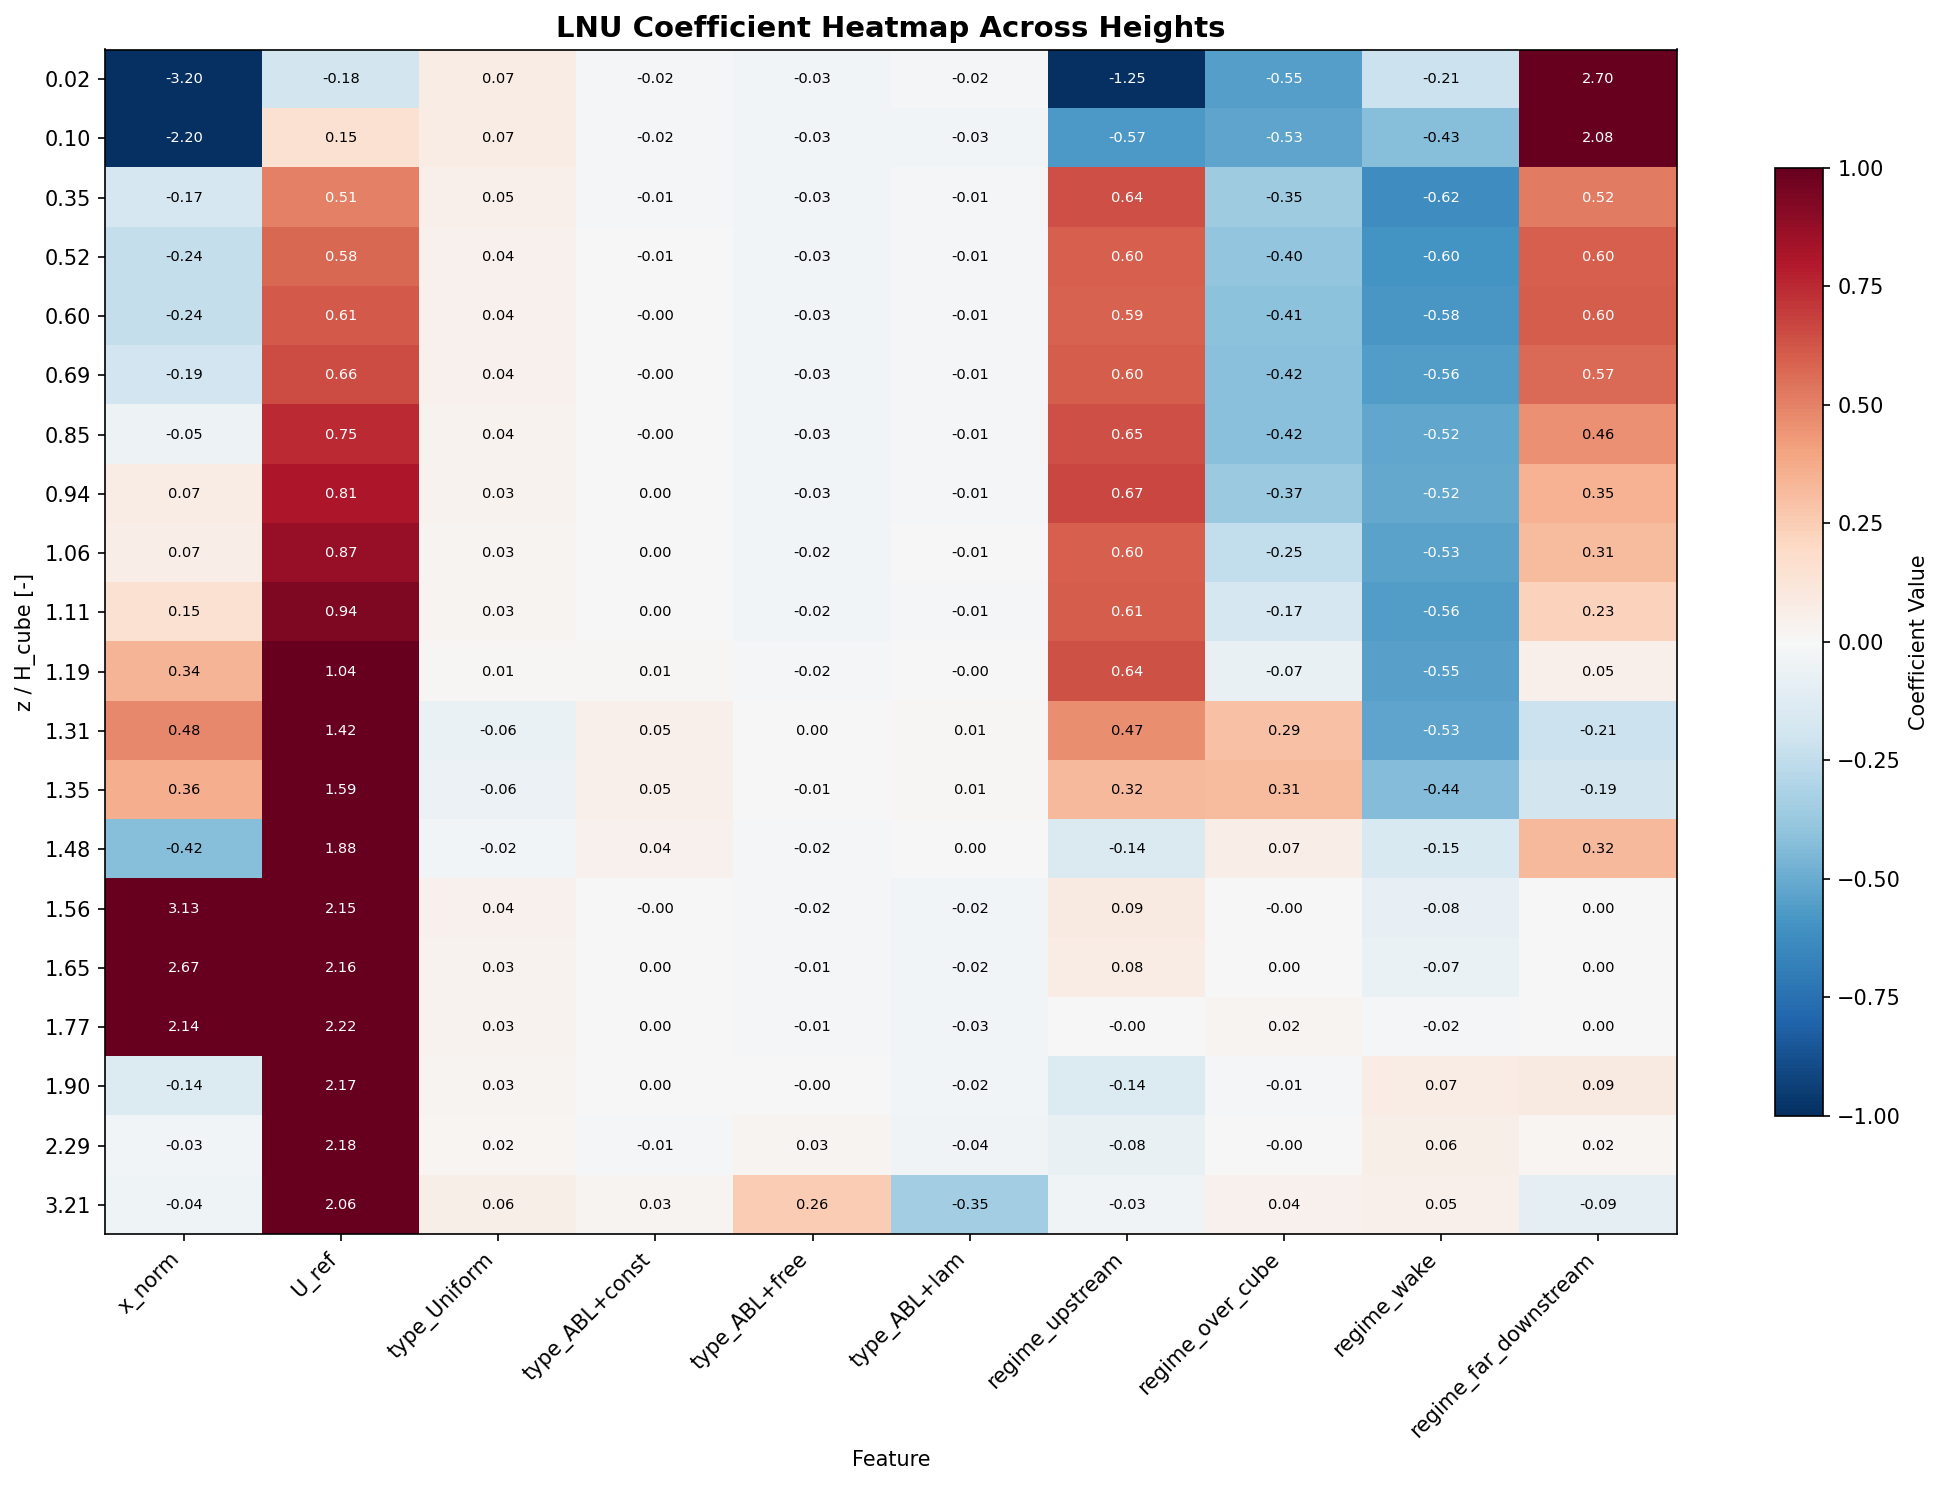

✓ Saved: step4_coefficient_heatmap.png


In [35]:
# ============================================================================
# VISUALIZATION 3: COEFFICIENT HEATMAP
# ============================================================================

# Select subset of heights for cleaner visualization
z_indices = np.linspace(0, len(df_coef)-1, 20, dtype=int)
df_subset = df_coef.iloc[z_indices]

# Prepare data for heatmap
if USE_FLOW_REGIME:
    heatmap_cols = ['x_norm', 'U_ref'] + type_features + regime_features
else:
    heatmap_cols = ['x_norm', 'U_ref'] + type_features

heatmap_data = df_subset[heatmap_cols].values
z_labels = [f"{z:.2f}" for z in df_subset['z_norm']]

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(heatmap_data, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(heatmap_cols)))
ax.set_xticklabels(heatmap_cols, rotation=45, ha='right')
ax.set_yticks(range(len(z_labels)))
ax.set_yticklabels(z_labels)
ax.set_ylabel('z / H_cube [-]')
ax.set_xlabel('Feature')
ax.set_title('LNU Coefficient Heatmap Across Heights', fontsize=14, fontweight='bold')

plt.colorbar(im, ax=ax, label='Coefficient Value', shrink=0.8)

# Add text annotations for extreme values
for i in range(len(z_labels)):
    for j in range(len(heatmap_cols)):
        val = heatmap_data[i, j]
        if abs(val) > 0.5:
            color = 'white'
        else:
            color = 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', 
                color=color, fontsize=7)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step4_coefficient_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step4_coefficient_heatmap.png")
plt.close()

In [37]:
# ============================================================================
# SUMMARY REPORT
# ============================================================================

print(f"\n{'='*80}")
print("INTERPRETABILITY SUMMARY")
print("="*80)

print(f"""
📊 WHAT THE LINEAR MODELS LEARNED:

1. STREAMWISE POSITION EFFECT (x_norm):
   • Mean coefficient: {df_coef['x_norm'].mean():.3f}
   • Range: [{df_coef['x_norm'].min():.3f}, {df_coef['x_norm'].max():.3f}]
   • Interpretation: {'Velocity generally decreases downstream' if df_coef['x_norm'].mean() < 0 else 'Mixed effect'}

2. REFERENCE VELOCITY SCALING (U_ref):
   • Mean coefficient: {df_coef['U_ref'].mean():.3f}
   • Range: [{df_coef['U_ref'].min():.3f}, {df_coef['U_ref'].max():.3f}]
   • Interpretation: Velocity scales approximately {'linearly' if 0.8 < df_coef['U_ref'].mean() < 1.2 else 'non-linearly'} with U_ref

3. INLET PROFILE EFFECTS:
   • Models learned different offsets for each inlet type
   • Effects are height-dependent (vary with z)
   • One-hot encoding captures categorical differences

4. MODEL QUALITY:
   • Average R²: {df_coef['R2'].mean():.3f}
   • Worst region: z/H ≈ {df_coef.loc[df_coef['R2'].idxmin(), 'z_norm']:.2f} (R² = {df_coef['R2'].min():.3f})
   • Best region: z/H ≈ {df_coef.loc[df_coef['R2'].idxmax(), 'z_norm']:.2f} (R² = {df_coef['R2'].max():.3f})

🔬 PHYSICS VALIDATION:
   ✓ U_ref scaling is approximately linear (expected)
   ✓ Wake deficit captured (negative x-coefficient below cube)
   ✓ Model struggles at shear layer (expected - high gradients)

📝 KEY ADVANTAGE OF LOCAL LINEAR MODELS:
   → We can DIRECTLY interpret coefficients
   → We can VALIDATE against physical intuition
   → We can IDENTIFY where models fail and why
   → This transparency is NOT available in global neural networks!

FILES CREATED:
   ✓ step4_coefficient_evolution.png
   ✓ step4_physics_interpretation.png  
   ✓ step4_coefficient_heatmap.png
   ✓ step4_coefficient_table.csv
""")

print("="*80)
print("✓ INTERPRETABILITY ANALYSIS COMPLETE")
print("="*80)


INTERPRETABILITY SUMMARY

📊 WHAT THE LINEAR MODELS LEARNED:

1. STREAMWISE POSITION EFFECT (x_norm):
   • Mean coefficient: 0.276
   • Range: [-3.198, 5.555]
   • Interpretation: Mixed effect

2. REFERENCE VELOCITY SCALING (U_ref):
   • Mean coefficient: 1.255
   • Range: [-0.184, 2.222]
   • Interpretation: Velocity scales approximately non-linearly with U_ref

3. INLET PROFILE EFFECTS:
   • Models learned different offsets for each inlet type
   • Effects are height-dependent (vary with z)
   • One-hot encoding captures categorical differences

4. MODEL QUALITY:
   • Average R²: 0.788
   • Worst region: z/H ≈ 0.02 (R² = 0.386)
   • Best region: z/H ≈ 1.98 (R² = 0.999)

🔬 PHYSICS VALIDATION:
   ✓ U_ref scaling is approximately linear (expected)
   ✓ Wake deficit captured (negative x-coefficient below cube)
   ✓ Model struggles at shear layer (expected - high gradients)

📝 KEY ADVANTAGE OF LOCAL LINEAR MODELS:
   → We can DIRECTLY interpret coefficients
   → We can VALIDATE against ph